In [29]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import squidpy as sq
import anndata as ad
import cellcharter as cc
import matplotlib.pyplot as plt

In [30]:
in_dir = "../../results/03_kidney_atlas/10_viz_cell2location"
out_dir = '../../results/04_spatial_clustering/01_run_cellcharter'

os.makedirs(out_dir, exist_ok=True)

In [31]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

In [ ]:
adata_list = []
for sample in sample_list:
    print(f'Processing sample {sample} ...')
    adata = sc.read_h5ad(f'{in_dir}/{sample}.h5ad')

    df = adata.obsm["q05_cell_abundance_w_sf"]
    adata.obsm["X_cell2location"] = df.div(df.sum(axis=1), axis=0)

    cc.gr.aggregate_neighbors(adata, n_layers=1, 
                              use_rep='X_cell2location', 
                              out_key='X_cellcharter')

    adata_list.append(adata)

Processing sample 15837 ...


100%|██████████| 2/2 [00:00<00:00, 1145.20it/s]


Processing sample 15852 ...


100%|██████████| 2/2 [00:00<00:00, 1048.97it/s]


Processing sample 16512 ...


...

100%|██████████| 2/2 [00:00<00:00, 2519.10it/s]


Processing sample X1899 ...


100%|██████████| 2/2 [00:00<00:00, 1716.87it/s]


Processing sample X1912 ...


100%|██████████| 2/2 [00:00<00:00, 2054.02it/s]


In [33]:
adata = ad.concat(adata_list, axis=0, merge='same', pairwise=True, index_unique='_')

In [34]:
adata.obsm["X_cellcharter"]

array([[8.1172042e-02, 2.6467426e-03, 5.6120637e-03, ..., 1.8698150e-02,
        2.5755117e-02, 9.2138104e-02],
       [1.1878435e-02, 1.7707588e-02, 2.1363606e-03, ..., 7.7991597e-03,
        3.5089161e-02, 1.9732300e-02],
       [6.3743154e-03, 1.1316914e-02, 4.3346584e-03, ..., 1.0757779e-02,
        4.9685270e-02, 7.5020343e-03],
       ...,
       [1.1928163e-03, 1.1078060e-02, 3.1830920e-04, ..., 3.1727289e-03,
        1.9165791e-04, 2.6043370e-02],
       [3.0235897e-04, 2.0756694e-03, 7.1601458e-03, ..., 4.6716951e-04,
        1.1921005e-04, 2.4648847e-03],
       [2.3632920e-03, 2.1198897e-05, 7.5084832e-04, ..., 3.1649055e-05,
        2.9259744e-01, 3.6882483e-03]], shape=(19740, 54), dtype=float32)

In [35]:
adata.obsm["X_cellcharter"].sum(axis=1)

array([1.9999999, 2.       , 2.       , ..., 2.       , 2.       ,
       1.9999999], shape=(19740,), dtype=float32)

In [36]:
autok = cc.tl.ClusterAutoK(
    n_clusters=(10, 15), 
    max_runs=10,
    convergence_tol=0.001
)

In [37]:
autok.fit(adata, use_rep='X_cellcharter')

Iteration 1/10


  0%|          | 0/8 [00:00<?, ?it/s]Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GP

Iteration 2/10


  0%|          | 0/8 [00:00<?, ?it/s]Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GP

Iteration 3/10


...

  0%|          | 0/8 [00:00<?, ?it/s]Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GP

Iteration 9/10


  0%|          | 0/8 [00:00<?, ?it/s]Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GP

Iteration 10/10


  0%|          | 0/8 [00:00<?, ?it/s]Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GP

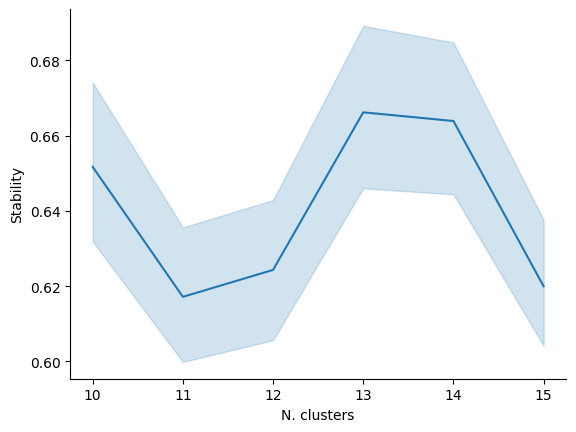

In [38]:
cc.pl.autok_stability(autok)

In [39]:
adata.obs['cluster_cellcharter'] = autok.predict(adata, use_rep='X_cellcharter')

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


In [40]:
adata.obs['cluster_cellcharter'].nunique()

13

In [41]:
adata.write_h5ad(f'{out_dir}/adata_cellcharter_merged.h5ad')

In [42]:
df_obs = adata.obs[['sample', 'cluster_cellcharter']]
df_obs.to_csv(f'{out_dir}/cellcharter_clusters_per_spot.tsv', sep='\t', index=True)

In [43]:
df_obs

,sample,cluster_cellcharter
AACCAAGGTATCAGGC-1_0,sample_15837,3
AACCGCCAGACTACTT-1_0,sample_15837,1
AACGAATTGACCGGTT-1_0,sample_15837,8
AACTCAACCTTGACCA-1_0,sample_15837,1
AACTGCCTCGATAGGT-1_0,sample_15837,1
...,...,...
TGTTCTGCTCTGTCGT-1_11,sample_X1912,12
TGTTGGAACCTTCCGC-1_11,sample_X1912,10
TGTTGGAACGAGGTCA-1_11,sample_X1912,10
TGTTGGATGGACTTCT-1_11,sample_X1912,11


In [44]:
os.makedirs(f"{out_dir}/samples", exist_ok=True)
os.makedirs(f"{out_dir}/plots", exist_ok=True)

for sample in sample_list:
    print(f'Processing sample {sample} ...')
    adata = sc.read_h5ad(f'{in_dir}/{sample}.h5ad')

    df_obs_sub = df_obs[df_obs["sample"] == f"sample_{sample}"]
    adata.obs["cluster_cellcharter"] = df_obs_sub["cluster_cellcharter"].values.tolist()

    adata.write_h5ad(f'{out_dir}/samples/{sample}.h5ad')

    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    sc.pl.spatial(adata, color="cluster_cellcharter", img_key='hires', alpha_img=1,
                  size=1, ax=ax, show=False, title=f'Sample {sample}')

    fig.savefig(f'{out_dir}/plots/spatial_clusters_{sample}.png', dpi=300)
    plt.close(fig)

Processing sample 15837 ...
Processing sample 15852 ...
Processing sample 16512 ...
Processing sample 21022 ...
Processing sample 8262 ...
Processing sample B23-03794-5 ...
Processing sample B23-05785-7-1 ...
Processing sample B23-05785-7-2 ...
Processing sample X1842 ...
Processing sample X1845 ...
Processing sample X1899 ...
Processing sample X1912 ...


In [45]:
adata

AnnData object with n_obs × n_vars = 834 × 1410
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', '_indices', '_scvi_batch', '_scvi_labels', 'ATL', 'CNT', 'DCT', 'DTL', 'EC', 'FIB', 'IC', 'IMM_B', 'IMM_MAC_M2', 'IMM_MAST', 'IMM_MDC', 'IMM_N', 'IMM_NKT', 'IMM_PL', 'IMM_T', 'IMM_cDC', 'IMM_cycMNP', 'IMM_ncMON', 'IMM_pDC', 'NEU', 'PC', 'PEC', 'POD', 'PT', 'PapE', 'TAL', 'VSM_P', 'cluster_cellcharter'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'MT_gene'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'mod', 'spatial', 'spatial_neighbors', 'cluster_cellcharter_colors'
    obsm: 'MT', 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance